# 03 · Feature engineering
**Owner:** Dhanvin Vadlamudi

Two kinds of features:
* **TF-IDF** on the premise and hypothesis text
* **Structured** features from the parsed facts and the PC graph (`src/features.py`)

TF-IDF and the scaler are fitted on train only and then applied to validation. Test is not used here.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"

from src.features import STRUCTURED_COLUMNS, add_structured_features, make_preprocessor

SEED = 42
train = add_structured_features(pd.read_csv(PROCESSED / "train.csv"))
validation = add_structured_features(pd.read_csv(PROCESSED / "validation.csv"))
print(train.shape, validation.shape)

(35340, 27) (1026, 27)


## 1. Structured features
For the two variables X and Y in each hypothesis: what type of claim it is, what the premise says about X and Y, whether
PC put an arrow between them, and `mec_support` (the share of possible graphs where the claim is true).

In [2]:
train[STRUCTURED_COLUMNS].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
parsed_num_variables,5.96,5.0,6.00
n_correlations,12.84,0.0,15.00
n_marginal_independencies,1.97,0.0,15.00
n_conditional_independencies,35.59,1.0,225.00
rel_direct_cause,0.33,0.0,1.00
rel_indirect_cause,0.33,0.0,1.00
rel_collider,0.17,0.0,1.00
rel_confounder,0.17,0.0,1.00
xy_correlated,0.87,0.0,1.00
xy_marginally_independent,0.13,0.0,1.00


No missing values. The columns are on different scales, so they are standardised (fitted on train).

## 2. TF-IDF: fit on train, transform validation
One vectorizer for the premise and one for the hypothesis. We keep single-letter tokens because A, B, C are the variable names.

In [3]:
pre = make_preprocessor("both")
X_train = pre.fit_transform(train, train["label"])   # learns the vocabulary from train
X_val = pre.transform(validation)                     # only applies it to validation
print("train:", X_train.shape, " validation:", X_val.shape)

train: (35340, 262)  validation: (1026, 262)


## 3. Feature selection
### Top TF-IDF terms (chi-squared, train)

In [4]:
for col in ["premise", "hypothesis"]:
    vec = pre.named_transformers_[f"{col}_tfidf"].named_steps["tfidf"]
    scores, _ = chi2(vec.transform(train[col]), train["label"])
    top = np.argsort(np.nan_to_num(scores))[::-1][:10]
    print(col, "->", list(vec.get_feature_names_out()[top]))

premise -> ['a e', 'given f', 'b e', 'of f', 'f a', 'c e', 'and b', 'b b', 'given e', 'c is']
hypothesis -> ['causes b', 'causes a', 'causes f', 'f directly', 'collider', 'collider i', 'effect', 'effect of', 'one collider', 'common effect']


The top terms are claim types ("collider") and variable letters. They don't link the hypothesis to what the premise
says about that pair, which is the actual reasoning needed.

### Structured features (mutual information, train)

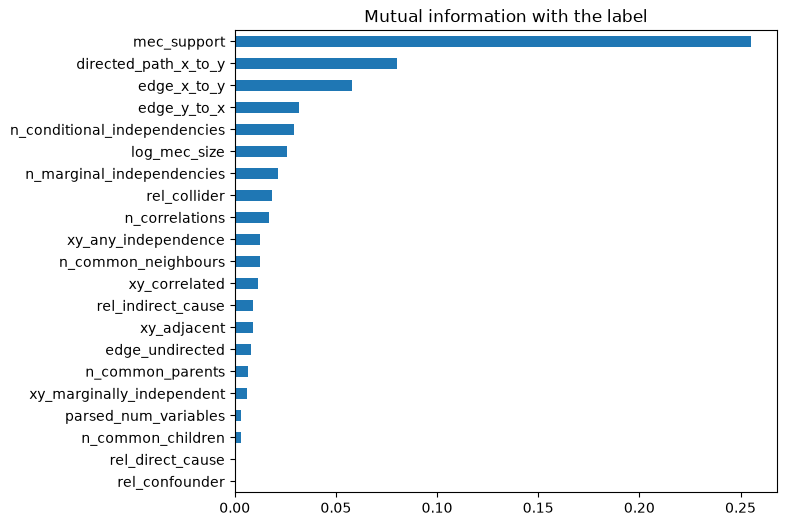

In [5]:
mi = pd.Series(mutual_info_classif(train[STRUCTURED_COLUMNS], train["label"], random_state=SEED),
               index=STRUCTURED_COLUMNS).sort_values()
mi.plot(kind="barh", figsize=(7, 6), title="Mutual information with the label")
plt.show()

### Does keeping only the top-k TF-IDF terms help?
Scored with 5-fold GroupKFold by premise on train, and on validation. The selector is inside the pipeline, so it is
re-fitted in every fold.

In [6]:
def evaluate(pre, name):
    model = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced"))
    cv = cross_val_score(model, train, train["label"], groups=train["premise_id"], cv=GroupKFold(5), scoring="f1")
    model.fit(train, train["label"])
    pred = model.predict(validation)
    return {"features": name, "cv F1": cv.mean(), "val precision": precision_score(validation["label"], pred),
            "val recall": recall_score(validation["label"], pred), "val F1": f1_score(validation["label"], pred)}


pd.DataFrame([
    evaluate(make_preprocessor("both"), "all terms"),
    evaluate(make_preprocessor("both", k_premise=50, k_hypothesis=30), "top 50 + 30 terms"),
]).round(3)

,features,cv F1,val precision,val recall,val F1
0,all terms,0.820,0.696,0.907,0.788
1,top 50 + 30 terms,0.798,0.680,0.938,0.788


Selection doesn't help (the vocabulary is already small), so we keep all terms.

## 4. Comparison: TF-IDF vs structured vs both

In [7]:
comparison = pd.DataFrame([
    evaluate(make_preprocessor("tfidf"), "TF-IDF only"),
    evaluate(make_preprocessor("structured"), "Structured only"),
    evaluate(make_preprocessor("both"), "TF-IDF + structured"),
]).round(3)
comparison

,features,cv F1,val precision,val recall,val F1
0,TF-IDF only,0.615,0.311,0.953,0.469
1,Structured only,0.775,0.658,0.953,0.778
2,TF-IDF + structured,0.820,0.696,0.907,0.788


TF-IDF alone does poorly because word counts can't do the causal reasoning. The structured features do much better,
and using both is best, so notebook 04 uses **TF-IDF + structured**.

## 5. Feature importance
Logistic Regression coefficients, and Random Forest permutation importance on validation.

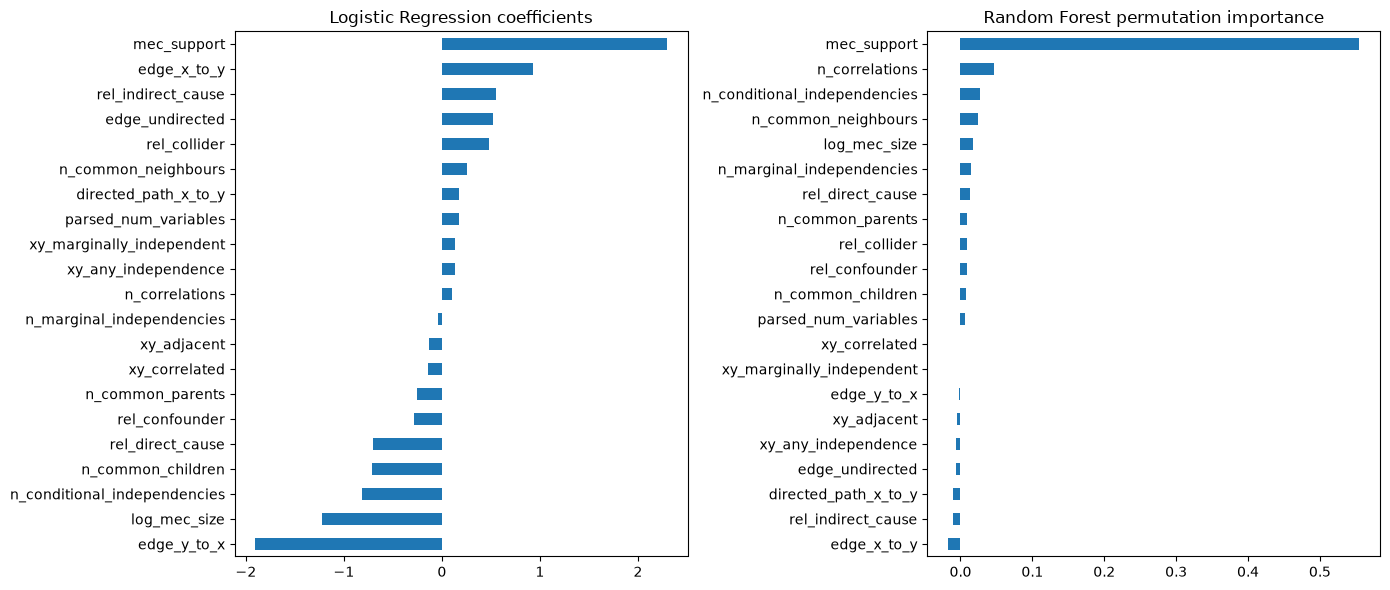

In [8]:
lr = make_pipeline(make_preprocessor("structured"), LogisticRegression(max_iter=2000, class_weight="balanced"))
lr.fit(train, train["label"])
coefs = pd.Series(lr[-1].coef_[0], index=STRUCTURED_COLUMNS).sort_values()

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(train[STRUCTURED_COLUMNS], train["label"])
perm = permutation_importance(rf, validation[STRUCTURED_COLUMNS], validation["label"], scoring="f1",
                              n_repeats=10, random_state=SEED)
perm = pd.Series(perm.importances_mean, index=STRUCTURED_COLUMNS).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
coefs.plot(kind="barh", ax=axes[0], title="Logistic Regression coefficients")
perm.plot(kind="barh", ax=axes[1], title="Random Forest permutation importance")
plt.tight_layout()
plt.show()

`mec_support` matters most. Logistic Regression also uses the edge direction (`edge_x_to_y` up, `edge_y_to_x` down).
The Random Forest relies almost entirely on `mec_support`, which already contains the edge information.